# PiggyCast: results notebook for review

This notebook goes through every result in the PiggyCast paper (`../../master_document.tex`). It is meant for co-authors and supervisors who want to check the numbers, look beyond the figures, and leave comments.

**How to run it**
```bash
cd PiggyCast_Arxiv_Paper/experiments
uv sync --group notebook                 # creates .venv with everything needed
uv run --group notebook jupyter lab notebooks/PiggyCast_results.ipynb
```
Sections 1–9 only read the precomputed results in `res/` (committed to the repo, about 3 MB), so they run in seconds. Section 10 (case-study explorer) also needs the raw WeatherBench 2 fields. Run `./run_all.sh` once to download them (about 270 MB) and regenerate everything in `res/` from scratch (about 10 minutes on a laptop CPU).

**Conventions used throughout**
* Variable: Z500 geopotential in **m² s⁻²** (divide by g ≈ 9.81 for geopotential height in metres). Grid: 5.625° (64 × 32), 12-hourly.
* Verification: ERA5. Anomalies are taken relative to the WeatherBench 2 1990–2019 ERA5 climatology.
* Evaluation: 10 rolling-origin folds (60-day training, 30-day test). All methods and lead times share the same test windows (8 Mar 2020 – 1 Jan 2021). The **leakage-safe gap** between training and test is 5 days + lead time (`gapsafe`); `gap5d` is the thesis protocol.
* RMSE = cos(latitude)-weighted RMSE per fold, averaged over the 10 folds (the thesis definition), unless stated otherwise.

**Method names**

| key | paper name | what it is |
|---|---|---|
| `neuralgcm`, `graphcast`, `pangu`, `ifshres` | base models | WB2 deterministic forecasts |
| `clim` | climatology | 1990–2019 ERA5 climatology |
| `mmm` | multi-model mean | equal-weight average of the 4 models |
| `lin` | linear stack | global area-weighted least squares on the 4 forecasts + intercept |
| `lin_clim` | **PiggyCast-Lin** | `lin` + climatology as a 6th regressor |
| `lin_pix` | per-grid-point linear | ridge regression on anomalies at every grid point (Krishnamurti superensemble) |
| `xgb_orig` | **PiggyCast-XGB** (thesis) | XGBoost on 4 forecasts + lon/lat, target = ERA5 |
| `xgb_nolatlon` | | the same without lon/lat |
| `xgb_resid` | **PiggyCast-XGB-R** | XGBoost predicts ERA5 − MMM from deviations from the MMM, the MMM anomaly, lon, lat |

> 💬 **Reviewers:** please add comments in markdown cells starting with `> 💬 [your initials]:` so they are easy to find with search.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # .../experiments
RES, DATA = ROOT / "res", ROOT / "data"
assert (RES / "results.csv").exists(), "res/ not found: run ./run_all.sh from experiments/ first"

pd.set_option("display.precision", 2, "display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.5, "lines.markersize": 4})
LEADS = np.arange(24, 241, 24)
# Same fixed encodings as the paper figures: base models in grays, combiners in four categorical hues.
BASE = {"neuralgcm": ("NeuralGCM", "#3b3a37", "o"), "graphcast": ("GraphCast", "#6d6c68", "s"),
        "ifshres": ("IFS HRES", "#9a9993", "^"), "pangu": ("Pangu-Weather", "#bdbcb6", "D")}
COMB = {"mmm": ("Multi-model mean", "#2a78d6", "o"), "lin_clim": ("PiggyCast-Lin", "#eb6834", "s"),
        "xgb_resid": ("PiggyCast-XGB-R", "#1baf7a", "^"), "xgb_orig": ("PiggyCast-XGB (thesis)", "#eda100", "D")}
STYLE = {**BASE, **COMB}
NAMES = {k: v[0] for k, v in STYLE.items()} | {"lin": "Linear stack", "lin_pix": "Per-grid-point linear",
                                               "xgb_nolatlon": "XGB without lon/lat", "clim": "Climatology"}
ORDER = ["neuralgcm", "graphcast", "ifshres", "pangu", "clim", "mmm", "lin", "lin_clim", "lin_pix",
         "xgb_orig", "xgb_nolatlon", "xgb_resid"]

lat = np.linspace(-87.1875, 87.1875, 32); lon = np.arange(0, 360, 5.625)
lon_e = np.append(lon, 360) - 5.625 / 2; lat_e = np.linspace(-90, 90, 33)
coslat = np.cos(np.deg2rad(lat))[:, None] * np.ones(64)
M = ["neuralgcm", "graphcast", "ifshres", "pangu"]
res = pd.read_csv(RES / "results.csv")
safe = res[res.gap == "gapsafe"]
def piv(col, df=safe):
    return df.pivot(index="lead", columns="method", values=col)[ORDER].rename(columns=NAMES)
print(f"{len(res)} result rows; gaps: {sorted(res.gap.unique())}; leads: {sorted(res.lead.unique())}")

240 result rows; gaps: ['gap5d', 'gapsafe']; leads: [np.int64(24), np.int64(48), np.int64(72), np.int64(96), np.int64(120), np.int64(144), np.int64(168), np.int64(192), np.int64(216), np.int64(240)]


## 1. Headline numbers (paper Table 2)

Fold-mean RMSE (m² s⁻²) with the leakage-safe gap. Rows are lead times (h). The best value in each row is highlighted.

In [2]:
rm = piv("rmse_foldmean")
rm.style.format("{:.1f}").highlight_min(axis=1, subset=rm.columns.drop("Climatology"), props="font-weight:bold;background-color:#d6e6f8")

method,NeuralGCM,GraphCast,IFS HRES,Pangu-Weather,Climatology,Multi-model mean,Linear stack,PiggyCast-Lin,Per-grid-point linear,PiggyCast-XGB (thesis),XGB without lon/lat,PiggyCast-XGB-R
lead,,,,,,,,,,,,
24,32.8,40.5,41.3,42.7,798.2,32.3,29.6,29.6,29.8,45.7,45.0,29.4
48,60.7,69.6,74.2,75.7,798.2,57.1,54.4,54.4,55.6,64.5,63.9,55.3
72,105.1,115.6,125.2,125.8,798.2,97.4,94.5,94.5,98.2,102.7,100.8,97.3
96,169.5,179.8,197.7,196.3,798.2,154.9,151.9,152.0,159.3,161.1,157.3,157.8
120,252.7,263.2,289.5,286.1,798.2,228.3,225.5,225.4,238.1,237.2,231.3,234.7
144,348.1,359.6,393.4,388.1,798.2,310.9,308.3,307.6,326.1,325.7,315.5,322.7
168,451.9,460.6,502.8,494.6,798.2,397.5,395.3,393.1,417.7,421.8,403.7,413.1
192,555.9,558.4,607.6,596.9,798.2,479.6,477.7,473.0,503.7,514.8,487.3,497.6
216,650.5,651.6,700.1,688.9,798.2,552.9,551.7,543.5,579.1,596.0,562.9,573.3


The same numbers as a **% change relative to the best single model at each lead** (negative = better). This is the quantity plotted in panel (a) of the skill figure.

In [3]:
best_single = rm[[NAMES[m] for m in BASE]].min(axis=1)
pct = 100 * (rm.drop(columns="Climatology").div(best_single, axis=0) - 1)
pct.style.format("{:+.1f}%").background_gradient(cmap="RdBu_r", vmin=-20, vmax=20)

method,NeuralGCM,GraphCast,IFS HRES,Pangu-Weather,Multi-model mean,Linear stack,PiggyCast-Lin,Per-grid-point linear,PiggyCast-XGB (thesis),XGB without lon/lat,PiggyCast-XGB-R
lead,,,,,,,,,,,
24,+0.0%,+23.5%,+26.2%,+30.4%,-1.4%,-9.6%,-9.7%,-9.1%,+39.4%,+37.4%,-10.1%
48,+0.0%,+14.7%,+22.2%,+24.7%,-5.9%,-10.4%,-10.5%,-8.4%,+6.2%,+5.1%,-9.0%
72,+0.0%,+10.0%,+19.1%,+19.7%,-7.3%,-10.0%,-10.1%,-6.6%,-2.3%,-4.0%,-7.4%
96,+0.0%,+6.1%,+16.6%,+15.8%,-8.6%,-10.4%,-10.4%,-6.1%,-5.0%,-7.2%,-6.9%
120,+0.0%,+4.2%,+14.6%,+13.2%,-9.6%,-10.8%,-10.8%,-5.8%,-6.1%,-8.5%,-7.1%
144,+0.0%,+3.3%,+13.0%,+11.5%,-10.7%,-11.4%,-11.6%,-6.3%,-6.4%,-9.4%,-7.3%
168,+0.0%,+1.9%,+11.3%,+9.4%,-12.0%,-12.5%,-13.0%,-7.6%,-6.7%,-10.7%,-8.6%
192,+0.0%,+0.5%,+9.3%,+7.4%,-13.7%,-14.1%,-14.9%,-9.4%,-7.4%,-12.3%,-10.5%
216,+0.0%,+0.2%,+7.6%,+5.9%,-15.0%,-15.2%,-16.4%,-11.0%,-8.4%,-13.5%,-11.9%


**Other aggregations.** The thesis averaged RMSE over folds. `rmse_pooled` (√ of the mean MSE over all test times) and `rmse_timemean` (mean of per-time RMSE, as WeatherBench 2 does) are also stored. Method rankings are unchanged; the differences are below 1%.

In [4]:
agg = safe[safe.method.isin(["neuralgcm", "mmm", "lin_clim", "xgb_orig", "xgb_resid"])]
agg = agg.set_index(["lead", "method"])[["rmse_foldmean", "rmse_pooled", "rmse_timemean"]].unstack("method")
agg.loc[[24, 72, 120, 240]].round(1)

rmse_foldmean                                     rmse_pooled                                     rmse_timemean                                    
method      lin_clim    mmm neuralgcm xgb_orig xgb_resid    lin_clim    mmm neuralgcm xgb_orig xgb_resid      lin_clim    mmm neuralgcm xgb_orig xgb_resid
lead                                                                                                                                                      
24              29.6   32.3      32.8     45.7      29.4        29.6   32.3      32.8     46.9      29.4          29.5   32.3      32.7     44.1      29.4
72              94.5   97.4     105.1    102.7      97.3        94.6   97.5     105.2    103.0      97.5          94.0   96.9     104.5    102.1      96.9
120            225.4  228.3     252.7    237.2     234.7       225.8  228.8     253.3    237.8     235.2         223.7  226.6     250.6    235.7     233.1
240            600.6  613.0     731.1    662.7     636.2       601.5  614.0     732.4    664.2     637.4         597.6  609.4     726.6    660.4     633.5

## 2. Skill against lead time: RMSE, ACC, activity (paper Fig. 3)

* **ACC** is the WB2-style uncentred anomaly correlation, area-weighted.
* **Activity ratio** is the area-weighted RMS of the forecast anomaly divided by that of the ERA5 anomaly. A value below 1 means the forecast is smoother than reality.

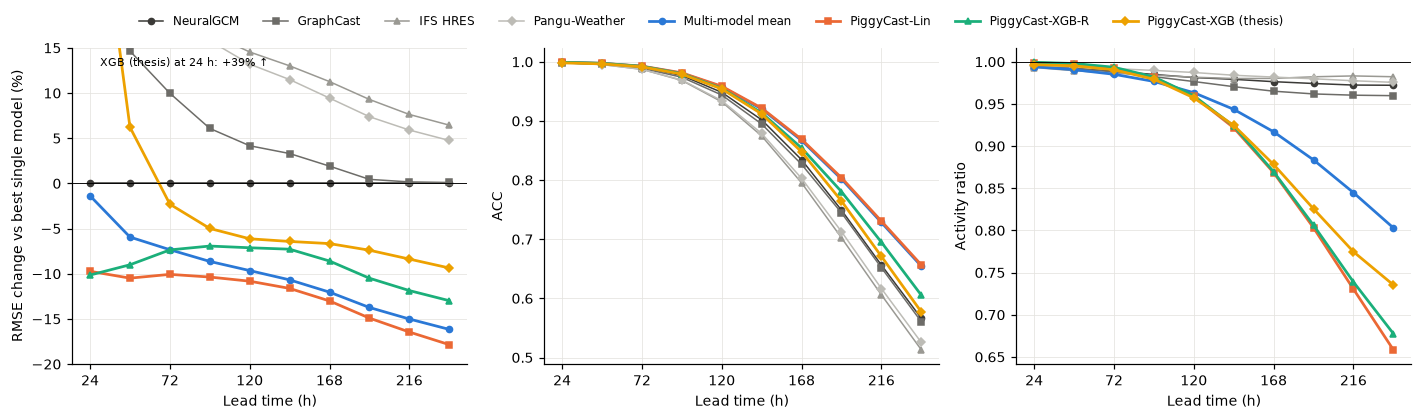

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
rmr, acc, act = (safe.pivot(index="lead", columns="method", values=c) for c in ("rmse_foldmean", "acc", "activity"))
bs = rmr[list(BASE)].min(axis=1)
for k, (lab, col, mk) in STYLE.items():
    lw = 1.0 if k in BASE else 1.8
    axs[0].plot(LEADS, 100 * (rmr[k] / bs - 1), color=col, marker=mk, lw=lw, label=lab)
    axs[1].plot(LEADS, acc[k], color=col, marker=mk, lw=lw)
    axs[2].plot(LEADS, act[k], color=col, marker=mk, lw=lw)
axs[0].axhline(0, c="k", lw=.6); axs[2].axhline(1, c="k", lw=.6)
axs[0].set_ylim(-20, 15); axs[0].annotate(f"XGB (thesis) at 24 h: {100*(rmr.xgb_orig[24]/bs[24]-1):+.0f}% ↑", (30, 13), fontsize=7); axs[0].set_ylabel("RMSE change vs best single model (%)")
axs[1].set_ylabel("ACC"); axs[2].set_ylabel("Activity ratio")
for a in axs: a.set_xlabel("Lead time (h)"); a.set_xticks(LEADS[::2])
fig.legend(loc="upper center", ncol=8, frameon=False, bbox_to_anchor=(0.5, 1.06), fontsize=8)
fig.tight_layout()

### 2a. Murphy (1988) check: is PiggyCast-Lin damping by the right amount?

For a forecast that minimises MSE, the activity ratio should equal the ACC (Murphy 1988). Compare the columns below. The multi-model mean damps by averaging but is not tuned. PiggyCast-Lin learns this damping through its climatology weight.

In [6]:
cmp = pd.concat({m: pd.DataFrame({"ACC": acc[m], "activity": act[m], "activity − ACC": act[m] - acc[m]})
                 for m in ["neuralgcm", "mmm", "lin_clim", "xgb_orig"]}, axis=1)
cmp.rename(columns=NAMES, level=0).style.format("{:.3f}")

### 2b. The best PiggyCast model against each raw model, days 1–10 (paper Figs. 5 and 6)

PiggyCast-Lin (the best combiner overall) compared directly with each of the four base models. The data come from `src/lin_vs_base.py`, which writes `res/lin_vs_base.csv` and `res/rmse_maps_lin_vs_base.npz` (grid-point RMSE maps of all five forecasts at every lead).

,NeuralGCM,GraphCast,IFS HRES,Pangu-Weather
day 1,9.7%,26.9%,28.5%,30.8%
day 2,10.5%,21.9%,26.7%,28.2%
day 3,10.1%,18.2%,24.5%,24.9%
day 4,10.4%,15.5%,23.1%,22.6%
day 5,10.8%,14.4%,22.1%,21.2%
day 6,11.6%,14.5%,21.8%,20.7%
day 7,13.0%,14.6%,21.8%,20.5%
day 8,14.9%,15.3%,22.1%,20.8%
day 9,16.4%,16.6%,22.4%,21.1%
day 10,17.8%,17.9%,22.8%,21.6%


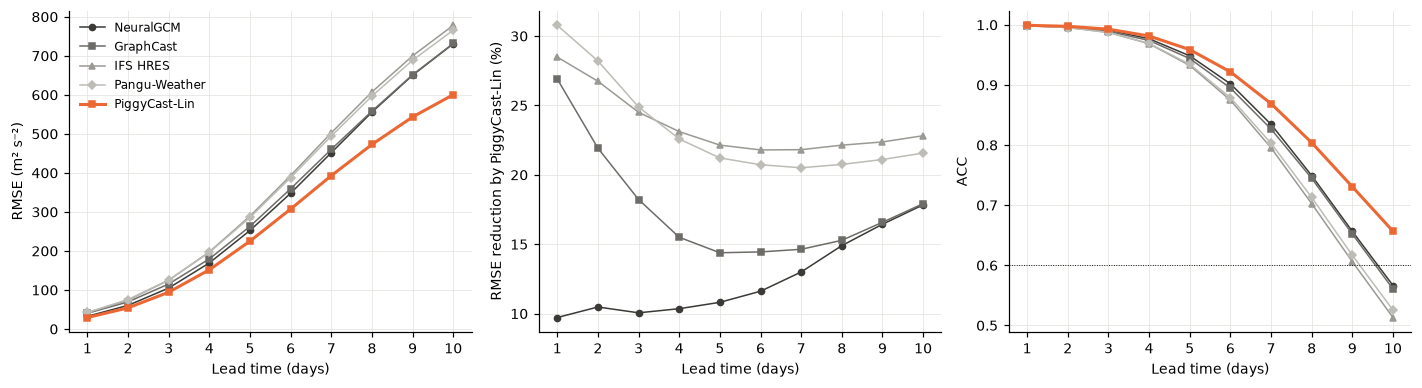

In [7]:
lb = pd.read_csv(RES / "lin_vs_base.csv")
rml = lb.pivot(index="lead", columns="method", values="rmse_foldmean")
accl = lb.pivot(index="lead", columns="method", values="acc")
red = pd.DataFrame({NAMES[m]: 100 * (1 - rml["lin_clim"] / rml[m]) for m in M})
red.index = [f"day {d}" for d in rml.index // 24]
display(red.style.format("{:.1f}%").background_gradient(cmap="Blues", vmin=0, vmax=32).set_caption("RMSE reduction by PiggyCast-Lin relative to each base model"))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
d = rml.index / 24
for m in M:
    lab, col, mk = BASE[m]
    axs[0].plot(d, rml[m], color=col, marker=mk, lw=1, label=lab)
    axs[1].plot(d, 100 * (1 - rml["lin_clim"] / rml[m]), color=col, marker=mk, lw=1, label=lab)
    axs[2].plot(d, accl[m], color=col, marker=mk, lw=1, label=lab)
for a, src in ((axs[0], rml), (axs[2], accl)):
    a.plot(d, src["lin_clim"], color=STYLE["lin_clim"][1], marker="s", lw=2, label="PiggyCast-Lin")
axs[2].axhline(0.6, color="k", lw=.6, ls=":")
axs[0].set_ylabel("RMSE (m² s⁻²)"); axs[1].set_ylabel("RMSE reduction by PiggyCast-Lin (%)"); axs[2].set_ylabel("ACC")
for a in axs: a.set_xlabel("Lead time (days)"); a.set_xticks(range(1, 11))
axs[0].legend(frameon=False, fontsize=8); fig.tight_layout()

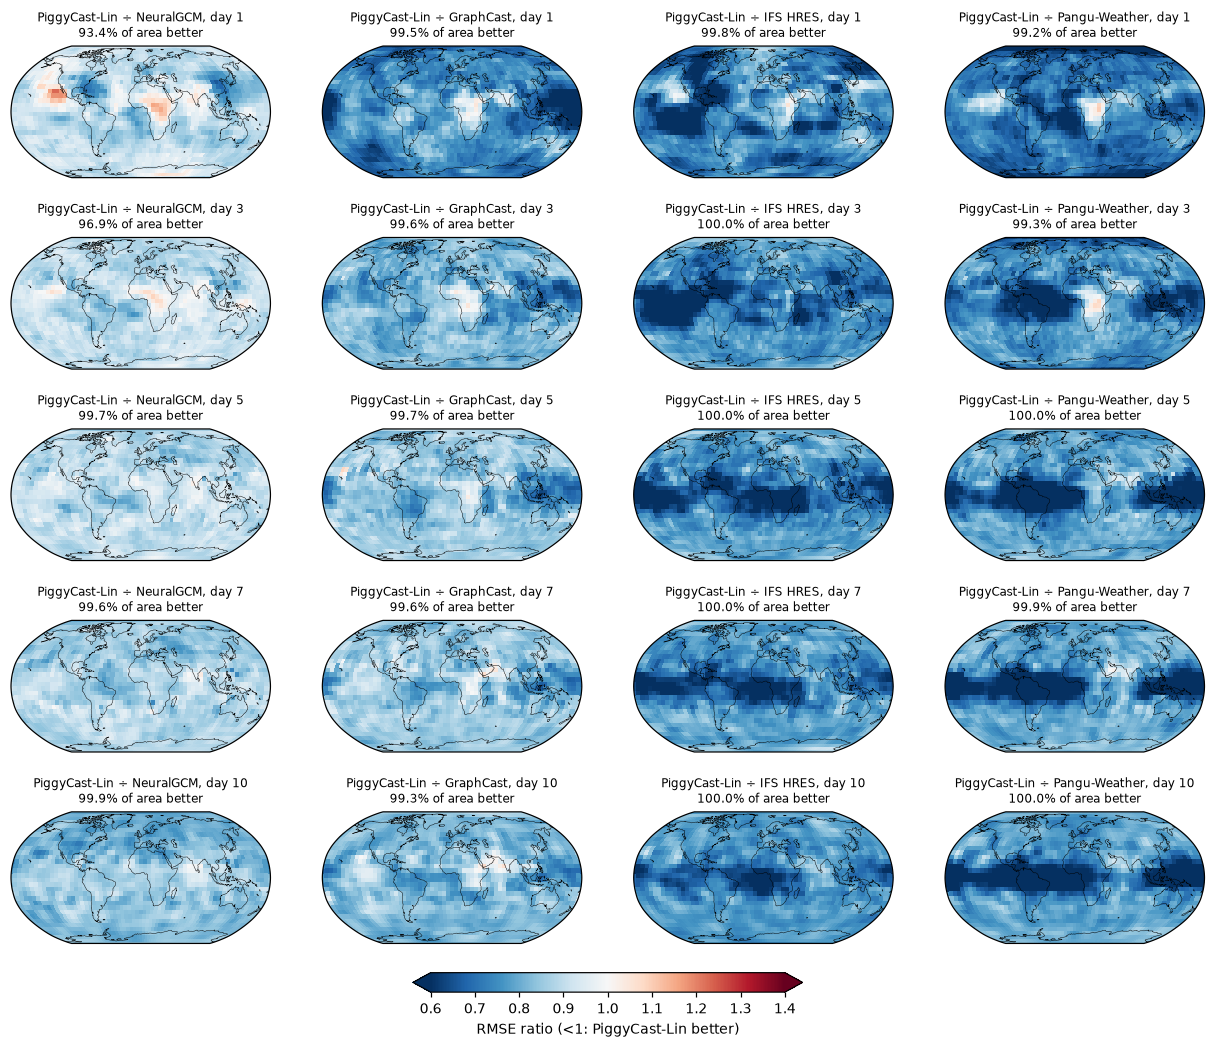

In [8]:
mb = np.load(RES / "rmse_maps_lin_vs_base.npz")
def lin_vs_base_map(day, model, ax=None):
    L = 24 * day
    r = mb[f"lin_clim_{L}"] / mb[f"{model}_{L}"]
    ax = ax or plt.figure(figsize=(6, 3.2)).add_subplot(projection=ccrs.Robinson())
    pc = ax.pcolormesh(lon_e, lat_e, r, cmap="RdBu_r", norm=TwoSlopeNorm(1, 0.6, 1.4), transform=ccrs.PlateCarree(), antialiased=False, linewidth=0)
    ax.coastlines(lw=.3); ax.set_global()
    ax.set_title(f"PiggyCast-Lin ÷ {NAMES[model]}, day {day}\n{100 * (coslat * (r < 1)).sum() / coslat.sum():.1f}% of area better", fontsize=8)
    return pc
# Any day 1-10 and any base model: edit the lists below.
days_show = [1, 3, 5, 7, 10]
fig, axs = plt.subplots(len(days_show), 4, figsize=(14, 2.3 * len(days_show)), subplot_kw=dict(projection=ccrs.Robinson()))
for i, dd in enumerate(days_show):
    for j, m in enumerate(M):
        pc = lin_vs_base_map(dd, m, axs[i, j])
fig.colorbar(pc, ax=axs, orientation="horizontal", fraction=.02, pad=.03, extend="both", label="RMSE ratio (<1: PiggyCast-Lin better)");

## 3. Statistical significance (paper Table 3)

Each cell gives the pooled RMSE difference A − B in m² s⁻², its 95% interval in brackets, and the same difference as a % of B. Confidence intervals come from a **moving-block bootstrap**: 10 consecutive 12-hourly steps (5 days) per block, 2000 resamples, 95% percentile intervals. ✱ marks intervals that exclude zero.

In [9]:
bt = pd.read_csv(RES / "bootstrap.csv")
bt["pair"] = bt.a.map(NAMES) + "  vs  " + bt.b.map(NAMES)
bt["cell"] = bt.apply(lambda r: f"{r['diff']:+.1f} [{r.lo:+.1f}, {r.hi:+.1f}] ({r.pct:+.1f}%){' ✱' if r.sig else ''}", axis=1)
bt.pivot(index="lead", columns="pair", values="cell")

pair,Linear stack vs Multi-model mean,Multi-model mean vs NeuralGCM,PiggyCast-Lin vs Multi-model mean,PiggyCast-Lin vs NeuralGCM,PiggyCast-XGB (thesis) vs Multi-model mean,PiggyCast-XGB (thesis) vs NeuralGCM,PiggyCast-XGB (thesis) vs PiggyCast-Lin,PiggyCast-XGB-R vs Multi-model mean
lead,,,,,,,,
24,"-2.7 [-2.9, -2.5] (-8.3%) ✱","-0.5 [-0.7, -0.2] (-1.4%) ✱","-2.7 [-2.9, -2.5] (-8.5%) ✱","-3.2 [-3.3, -3.1] (-9.7%) ✱","+14.5 [+10.5, +18.9] (+45.0%) ✱","+14.1 [+10.0, +18.5] (+43.0%) ✱","+17.3 [+13.2, +21.7] (+58.4%) ✱","-2.9 [-3.0, -2.7] (-8.9%) ✱"
48,"-2.7 [-2.9, -2.5] (-4.8%) ✱","-3.6 [-4.1, -3.2] (-5.9%) ✱","-2.8 [-3.0, -2.5] (-4.8%) ✱","-6.4 [-6.7, -6.1] (-10.5%) ✱","+7.8 [+5.3, +10.7] (+13.7%) ✱","+4.2 [+1.6, +7.2] (+6.9%) ✱","+10.6 [+8.0, +13.6] (+19.4%) ✱","-1.9 [-2.1, -1.6] (-3.3%) ✱"
72,"-2.9 [-3.2, -2.5] (-2.9%) ✱","-7.7 [-8.8, -6.9] (-7.3%) ✱","-2.9 [-3.2, -2.5] (-2.9%) ✱","-10.6 [-11.4, -9.9] (-10.1%) ✱","+5.5 [+3.8, +7.5] (+5.7%) ✱","-2.2 [-4.2, -0.2] (-2.1%) ✱","+8.4 [+6.6, +10.4] (+8.9%) ✱","-0.0 [-0.4, +0.4] (-0.0%)"
96,"-2.9 [-3.4, -2.4] (-1.9%) ✱","-14.7 [-16.7, -13.0] (-8.6%) ✱","-2.9 [-3.4, -2.4] (-1.9%) ✱","-17.6 [-19.2, -16.2] (-10.4%) ✱","+6.4 [+4.7, +8.2] (+4.1%) ✱","-8.3 [-10.7, -6.2] (-4.9%) ✱","+9.3 [+7.5, +11.2] (+6.1%) ✱","+2.9 [+2.3, +3.7] (+1.9%) ✱"
120,"-2.8 [-3.4, -2.1] (-1.2%) ✱","-24.5 [-27.7, -21.7] (-9.7%) ✱","-2.9 [-3.5, -2.2] (-1.3%) ✱","-27.4 [-30.1, -25.1] (-10.8%) ✱","+9.0 [+7.8, +10.6] (+3.9%) ✱","-15.5 [-18.3, -12.6] (-6.1%) ✱","+11.9 [+10.8, +13.3] (+5.3%) ✱","+6.5 [+5.5, +7.7] (+2.8%) ✱"
144,"-2.5 [-3.3, -1.6] (-0.8%) ✱","-37.3 [-41.9, -33.2] (-10.7%) ✱","-3.3 [-4.1, -2.2] (-1.0%) ✱","-40.6 [-44.4, -37.0] (-11.6%) ✱","+15.0 [+13.0, +17.2] (+4.8%) ✱","-22.3 [-26.9, -18.0] (-6.4%) ✱","+18.2 [+16.3, +20.2] (+5.9%) ✱","+11.9 [+10.2, +13.9] (+3.8%) ✱"
168,"-2.2 [-3.0, -1.2] (-0.6%) ✱","-54.6 [-59.6, -49.7] (-12.1%) ✱","-4.4 [-5.4, -3.2] (-1.1%) ✱","-59.0 [-63.5, -54.5] (-13.0%) ✱","+24.6 [+21.5, +28.6] (+6.2%) ✱","-30.0 [-35.2, -24.1] (-6.6%) ✱","+29.0 [+25.9, +32.6] (+7.4%) ✱","+15.7 [+13.4, +18.1] (+3.9%) ✱"
192,"-1.9 [-2.7, -1.0] (-0.4%) ✱","-76.5 [-81.6, -71.7] (-13.7%) ✱","-6.6 [-7.9, -5.0] (-1.4%) ✱","-83.1 [-87.7, -78.4] (-14.9%) ✱","+35.6 [+30.4, +41.5] (+7.4%) ✱","-41.0 [-47.6, -33.9] (-7.4%) ✱","+42.1 [+37.1, +47.5] (+8.9%) ✱","+18.2 [+15.2, +21.4] (+3.8%) ✱"
216,"-1.2 [-2.0, -0.3] (-0.2%) ✱","-97.9 [-104.4, -91.5] (-15.0%) ✱","-9.4 [-11.3, -7.2] (-1.7%) ✱","-107.3 [-113.2, -100.9] (-16.5%) ✱","+43.7 [+38.5, +49.5] (+7.9%) ✱","-54.2 [-61.2, -46.5] (-8.3%) ✱","+53.1 [+48.2, +58.4] (+9.8%) ✱","+20.7 [+17.3, +24.8] (+3.7%) ✱"


Pairs that are **not** significant:

In [10]:
bt.loc[~bt.sig, ["lead", "pair", "diff", "lo", "hi"]].round(2)

,lead,pair,diff,lo,hi
21,72,PiggyCast-XGB-R vs Multi-model mean,-0.00,-0.36,0.41
78,240,Linear stack vs Multi-model mean,-0.34,-1.18,0.50


## 4. Why averaging helps: error correlation (paper Fig. 2)

The correlations below are between the forecast-error fields of each pair of base models (uncentred, area-weighted, full common window). Errors that are only moderately correlated (about 0.5–0.6) are what makes the average work.

If model *i* has error variance σᵢ², the MSE of the multi-model mean is (1/M²) Σᵢⱼ ρᵢⱼ σᵢ σⱼ. With equal σ this becomes σ²(1 + (M−1)ρ̄)/M. Below, σᵢ comes from the stored RMSEs, so this check is close but not exact: the correlations use the whole window, while the RMSEs use only the test window.

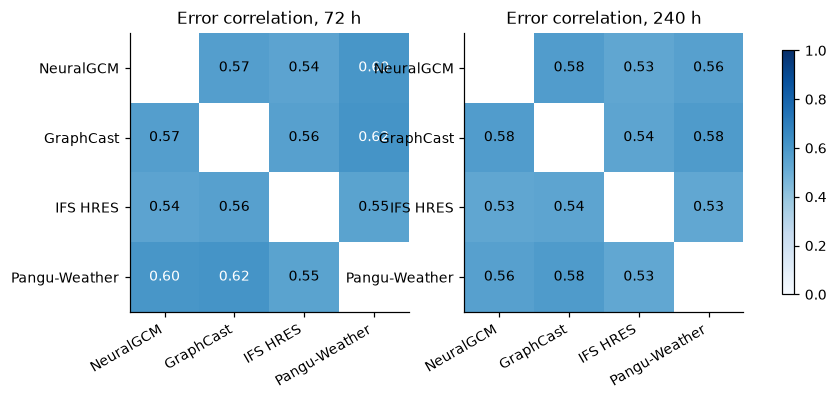

,lead,mean_offdiag_rho,predicted_mmm_rmse,actual_mmm_rmse,best_single
0,72,0.57,97.34,97.46,105.16
1,240,0.56,614.37,613.98,732.44


In [11]:
M = ["neuralgcm", "graphcast", "ifshres", "pangu"]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
rows = []
for ax, L in zip(axs, [72, 240]):
    C = np.load(RES / f"errcorr_{L}.npy")
    im = ax.imshow(np.where(np.eye(4, dtype=bool), np.nan, C), cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            if i != j: ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", color="w" if C[i, j] > .6 else "k")
    ax.set_xticks(range(4), [NAMES[m] for m in M], rotation=30, ha="right"); ax.set_yticks(range(4), [NAMES[m] for m in M])
    ax.grid(False); ax.set_title(f"Error correlation, {L} h")
    pooled = safe[safe.lead == L].set_index("method").rmse_pooled
    s = pooled[M].values
    rows.append(dict(lead=L, mean_offdiag_rho=C[~np.eye(4, dtype=bool)].mean(),
                     predicted_mmm_rmse=np.sqrt(s @ C @ s) / 4, actual_mmm_rmse=pooled["mmm"],
                     best_single=pooled[M].min()))
fig.colorbar(im, ax=axs, shrink=.8); plt.show()
pd.DataFrame(rows).round(3)

### 4a. Hierarchical clustering and why the MDS figure was dropped

The thesis showed a 2-D MDS embedding of all model–lead combinations. The table below gives its Kruskal stress-1. Values above about 0.2 mean the 2-D picture distorts the true distances badly, so the paper reports the stress instead of showing the plot. The UPGMA dendrogram at 72 h shows the same grouping without that distortion.

MDS Kruskal stress-1: 0.243


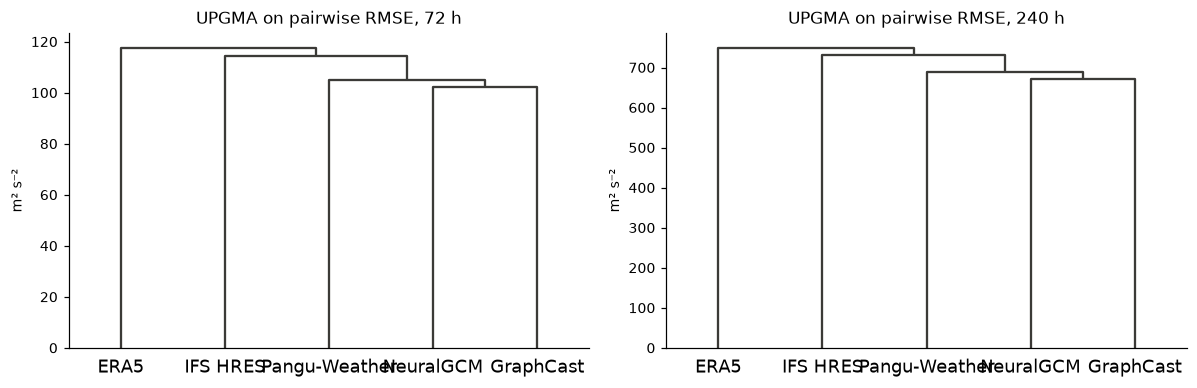

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
names = json.load(open(RES / "pairwise_names.json")); D = np.load(RES / "pairwise_rmse.npy"); X = np.load(RES / "mds_coords.npy")
iu = np.triu_indices_from(D, 1); dh = np.sqrt(((X[:, None] - X[None]) ** 2).sum(-1))
print("MDS Kruskal stress-1:", round(np.sqrt(((D[iu] - dh[iu]) ** 2).sum() / (D[iu] ** 2).sum()), 3))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, L in zip(axs, [72, 240]):
    sel = [names.index(f"{m}_{L}") for m in M] + [names.index("era5")]
    dendrogram(linkage(squareform(D[np.ix_(sel, sel)], checks=False), "average"),
               labels=[NAMES[m] for m in M] + ["ERA5"], ax=ax, color_threshold=0, above_threshold_color="#3b3a37")
    ax.set_title(f"UPGMA on pairwise RMSE, {L} h"); ax.set_ylabel("m² s⁻²"); ax.grid(False)
fig.tight_layout()

## 5. Leakage: thesis 5-day gap against the leakage-safe gap (paper Appendix A)

With rows indexed by valid time, a training sample at lead L comes from a forecast initialised L hours earlier. If the gap between training and test is shorter than L, the last training targets overlap the period the test forecasts cover. Values are the change in fold-mean RMSE when moving from `gap5d` to `gapsafe` (positive = the thesis protocol looked better than it should have).

In [13]:
g = res.pivot_table(index=["lead", "method"], columns="gap", values="rmse_foldmean")
leak = (100 * (g.gapsafe / g.gap5d - 1)).unstack("method")[["mmm", "lin", "lin_clim", "lin_pix", "xgb_orig", "xgb_nolatlon", "xgb_resid"]]
leak.rename(columns=NAMES).style.format("{:+.2f}%").background_gradient(cmap="Reds", vmin=0, vmax=3)

method,Multi-model mean,Linear stack,PiggyCast-Lin,Per-grid-point linear,PiggyCast-XGB (thesis),XGB without lon/lat,PiggyCast-XGB-R
lead,,,,,,,
24,+0.00%,+0.01%,+0.01%,+0.09%,+0.58%,+0.61%,+0.07%
48,+0.00%,+0.01%,+0.01%,+0.10%,+0.20%,+0.20%,+0.02%
72,+0.00%,+0.01%,+0.01%,+0.11%,+0.72%,+0.28%,+0.18%
96,+0.00%,+0.01%,+0.01%,+0.08%,+0.75%,+0.06%,+0.20%
120,+0.00%,+0.02%,+0.02%,+0.10%,+0.09%,+0.10%,-0.01%
144,+0.00%,+0.03%,+0.02%,+0.07%,+0.27%,+0.08%,+0.06%
168,+0.00%,+0.03%,+0.03%,+0.14%,+0.66%,+0.08%,+0.07%
192,+0.00%,+0.03%,+0.04%,+0.20%,+1.58%,+0.08%,+0.17%
216,+0.00%,+0.03%,+0.05%,+0.22%,+2.09%,+0.13%,+0.19%


## 6. Is the gain consistent over time? Folds and time series

The paper reports averages. Below are the per-fold RMSEs and a 15-day running RMSE over the test period, to show whether one fold or one season drives the result.

In [14]:
def fold_table(lead, methods=("neuralgcm", "mmm", "lin_clim", "xgb_orig", "xgb_resid")):
    d = safe[(safe.lead == lead) & safe.method.isin(methods)].set_index("method")
    t = pd.DataFrame({NAMES[m]: json.loads(d.loc[m, "fold_rmse"]) for m in methods})
    t.index = [f"fold {k}" for k in range(len(t))]
    return t
for L in (72, 240):
    t = fold_table(L)
    print(f"\n{L} h: PiggyCast-Lin beats NeuralGCM in {(t['PiggyCast-Lin'] < t['NeuralGCM']).sum()}/10 folds, "
          f"beats MMM in {(t['PiggyCast-Lin'] < t['Multi-model mean']).sum()}/10; "
          f"XGB (thesis) beats MMM in {(t['PiggyCast-XGB (thesis)'] < t['Multi-model mean']).sum()}/10")
    display(t.round(1))


72 h: PiggyCast-Lin beats NeuralGCM in 10/10 folds, beats MMM in 10/10; XGB (thesis) beats MMM in 0/10


,NeuralGCM,Multi-model mean,PiggyCast-Lin,PiggyCast-XGB (thesis),PiggyCast-XGB-R
fold 0,107.7,101.5,97.3,118.0,101.2
fold 1,111.0,103.0,100.2,108.4,104.3
fold 2,107.5,98.8,96.5,102.6,98.3
fold 3,109.9,99.5,97.5,111.3,100.0
fold 4,108.1,98.7,96.4,103.5,99.4
fold 5,104.0,100.5,96.8,102.7,100.0
fold 6,101.9,95.9,92.9,97.9,96.3
fold 7,103.6,95.0,92.5,99.0,94.7
fold 8,100.8,92.0,88.9,93.8,90.8
fold 9,96.4,88.7,86.1,89.4,88.5



240 h: PiggyCast-Lin beats NeuralGCM in 10/10 folds, beats MMM in 10/10; XGB (thesis) beats MMM in 0/10


,NeuralGCM,Multi-model mean,PiggyCast-Lin,PiggyCast-XGB (thesis),PiggyCast-XGB-R
fold 0,799.6,656.7,641.0,708.0,687.9
fold 1,815.7,682.7,666.6,751.5,710.3
fold 2,731.3,630.2,617.0,695.3,656.7
fold 3,690.7,583.5,570.0,634.1,616.6
fold 4,697.7,581.8,574.1,622.3,594.5
fold 5,705.1,595.0,583.7,603.7,610.8
fold 6,744.8,623.4,609.1,685.9,643.4
fold 7,738.3,612.4,600.0,664.4,645.5
fold 8,722.1,603.1,592.8,654.6,617.2
fold 9,665.6,561.1,552.1,607.1,579.3


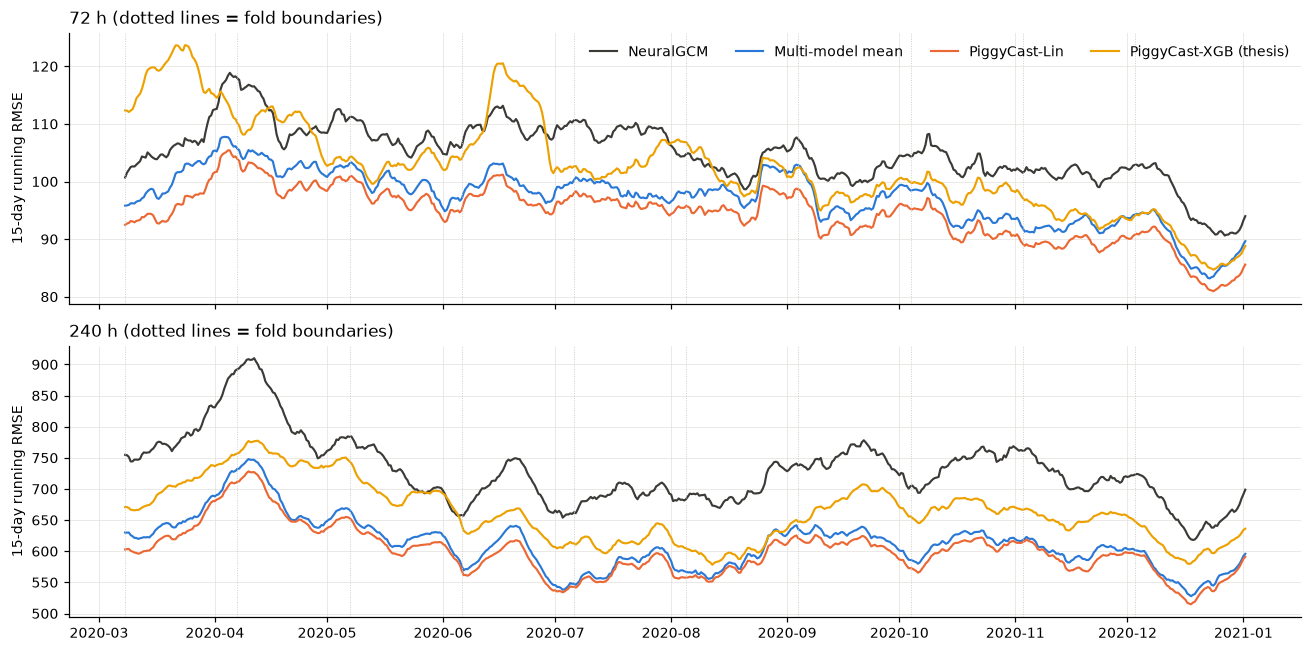

In [15]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, L in zip(axs, (72, 240)):
    z = np.load(RES / f"mse_series_gapsafe_{L}.npz")
    t = pd.to_datetime(z["times"])
    for k in ["neuralgcm", "mmm", "lin_clim", "xgb_orig"]:
        lab, col, _ = STYLE[k]
        ax.plot(t, np.sqrt(pd.Series(z[k], index=t).rolling(30, center=True, min_periods=10).mean()), color=col, label=lab, lw=1.4)
    for k in range(0, len(t), 60):
        ax.axvline(t[k], color="#c8c7c2", lw=.6, ls=":")
    ax.set_ylabel("15-day running RMSE"); ax.set_title(f"{L} h (dotted lines = fold boundaries)", loc="left")
axs[0].legend(ncol=4, frameon=False); fig.tight_layout()

## 7. Where is the gain? RMSE-ratio maps (paper Fig. 4)

`ratio_map(lead, num, den)` plots RMSE(num)/RMSE(den) at each grid point over the test period. Blue means the numerator is better. Maps are stored for `neuralgcm, graphcast, mmm, lin_clim, lin_pix, xgb_orig, xgb_resid`. Edit the calls to look at other pairs or lead times.

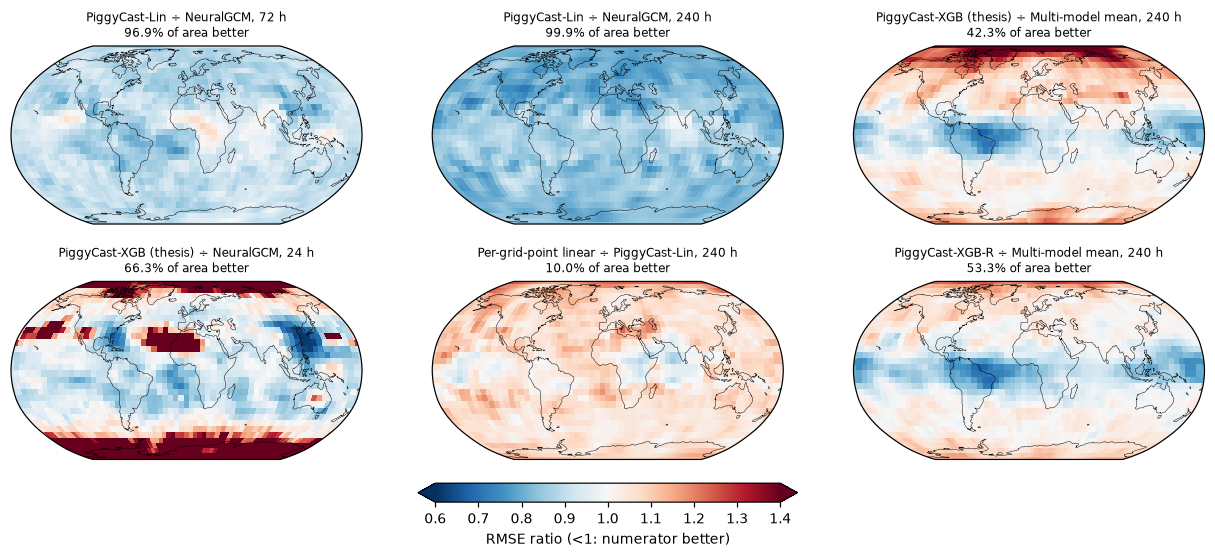

In [16]:
lat = np.linspace(-87.1875, 87.1875, 32); lon = np.arange(0, 360, 5.625)
lon_e = np.append(lon, 360) - 5.625 / 2; lat_e = np.linspace(-90, 90, 33)
coslat = np.cos(np.deg2rad(lat))[:, None] * np.ones(64)

def ratio_map(lead, num, den, ax=None, gap="gapsafe", vmin=0.6, vmax=1.4):
    mp = np.load(RES / f"rmse_maps_{gap}_{lead}.npz")
    r = mp[num] / mp[den]
    ax = ax or plt.figure(figsize=(6, 3.2)).add_subplot(projection=ccrs.Robinson())
    pc = ax.pcolormesh(lon_e, lat_e, r, cmap="RdBu_r", norm=TwoSlopeNorm(1, vmin, vmax), transform=ccrs.PlateCarree())
    ax.coastlines(lw=.3); ax.set_global()
    better = (coslat * (r < 1)).sum() / coslat.sum()
    ax.set_title(f"{NAMES[num]} ÷ {NAMES[den]}, {lead} h\n{100*better:.1f}% of area better", fontsize=8)
    return pc

fig, axs = plt.subplots(2, 3, figsize=(14, 5.6), subplot_kw=dict(projection=ccrs.Robinson()))
panels = [(72, "lin_clim", "neuralgcm"), (240, "lin_clim", "neuralgcm"), (240, "xgb_orig", "mmm"),
          (24, "xgb_orig", "neuralgcm"), (240, "lin_pix", "lin_clim"), (240, "xgb_resid", "mmm")]
for ax, p in zip(axs.ravel(), panels):
    pc = ratio_map(*p, ax=ax)
fig.colorbar(pc, ax=axs, orientation="horizontal", fraction=.04, pad=.05, extend="both", label="RMSE ratio (<1: numerator better)");

### 7a. Zonal view: area-weighted RMSE by latitude band

This quantifies the map pattern: the thesis XGBoost loses most at high latitudes, where Z500 variability and extremes are largest.

In [17]:
bands = {"90S–60S": (-90, -60), "60S–30S": (-60, -30), "30S–30N": (-30, 30), "30N–60N": (30, 60), "60N–90N": (60, 90)}
rows = []
for L in (24, 72, 240):
    mp = np.load(RES / f"rmse_maps_gapsafe_{L}.npz")
    for b, (lo_, hi_) in bands.items():
        sel = (lat >= lo_) & (lat < hi_)
        w_ = coslat[sel]
        r = {k: np.sqrt((mp[k][sel] ** 2 * w_).sum() / w_.sum()) for k in mp.files}
        rows.append(dict(lead=L, band=b, **{f"{NAMES[k]} vs MMM (%)": 100 * (r[k] / r["mmm"] - 1)
                                             for k in ["neuralgcm", "lin_clim", "lin_pix", "xgb_orig", "xgb_resid"]}))
pd.DataFrame(rows).set_index(["lead", "band"]).style.format("{:+.1f}").background_gradient(cmap="RdBu_r", vmin=-30, vmax=30)

## 8. What the stacks learn: linear weights and SHAP (paper Fig. 6)

* **PiggyCast-Lin weights.** Mean ± standard deviation across the 10 folds. The intercept (in m² s⁻²) corrects the overall bias. As lead time grows, the model weights become nearly equal and the climatology weight increases, which is learned damping.
* **PiggyCast-XGB SHAP.** Mean |SHAP| from TreeSHAP on 20,000 area-weighted test samples, folds 0, 4 and 9. Latitude gains importance with lead time: the trees use location to emulate climatology.

,NeuralGCM,GraphCast,IFS HRES,Pangu-Weather,Climatology,intercept,sum of model weights
lead,,,,,,,
24,0.586,0.209,0.147,0.061,-0.002,-97.725,1.004
48,0.504,0.263,0.181,0.058,-0.003,-152.433,1.005
72,0.468,0.274,0.188,0.076,-0.002,-190.214,1.006
96,0.432,0.286,0.193,0.092,0.001,-220.494,1.003
120,0.397,0.281,0.197,0.117,0.012,-243.383,0.992
144,0.372,0.271,0.192,0.136,0.034,-266.401,0.971
168,0.335,0.268,0.185,0.151,0.066,-299.609,0.939
192,0.293,0.264,0.175,0.166,0.108,-344.661,0.898
216,0.265,0.243,0.171,0.172,0.158,-413.274,0.850


,GraphCast,Pangu-Weather,NeuralGCM,IFS HRES,longitude,latitude
lead,,,,,,
24,639.2,170.3,1102.4,361.6,4.3,3.0
48,700.6,115.0,984.1,428.4,5.5,4.4
72,668.8,163.0,993.8,404.9,7.4,5.4
96,630.3,293.8,955.4,362.5,11.0,11.8
120,590.6,298.0,951.5,393.3,16.9,18.1
144,521.3,335.4,1051.7,307.1,23.1,35.6
168,568.4,501.3,916.6,242.0,30.9,60.3
192,607.2,389.5,878.1,283.3,42.5,99.3
216,446.4,376.2,989.7,333.5,47.6,139.2


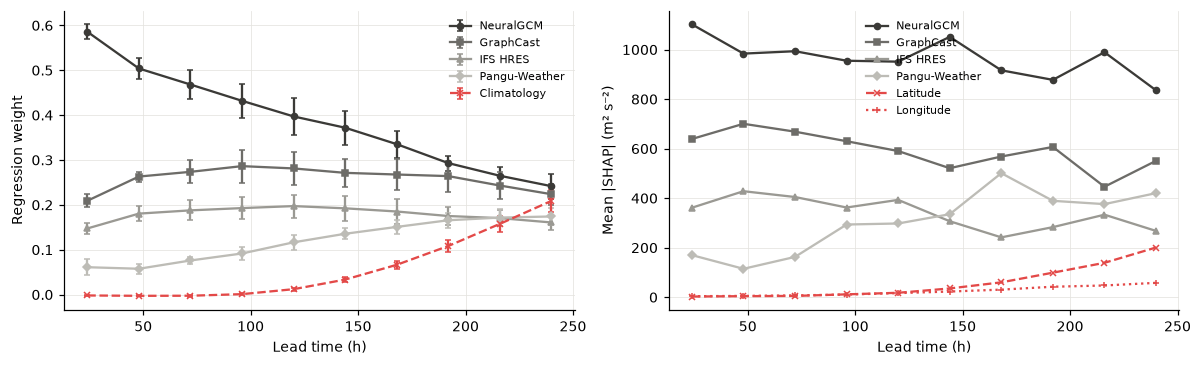

In [18]:
co = pd.read_csv(RES / "lin_clim_coefs.csv")
w_mean = co.groupby("lead")[M + ["clim", "intercept"]].mean(); w_std = co.groupby("lead")[M + ["clim"]].std()
w_mean["sum of model weights"] = w_mean[M].sum(axis=1)
display(w_mean.rename(columns=NAMES).style.format("{:.3f}"))
sh = pd.read_csv(RES / "shap_xgb_orig.csv").groupby("lead").mean().drop(columns="fold")
display(sh.rename(columns=NAMES).round(1))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for m in M:
    lab, col, mk = BASE[m]
    axs[0].errorbar(LEADS, w_mean[m], yerr=w_std[m], color=col, marker=mk, capsize=2, label=lab)
    axs[1].plot(LEADS, sh[m], color=col, marker=mk, label=lab)
axs[0].errorbar(LEADS, w_mean["clim"], yerr=w_std["clim"], color="#e34948", marker="x", ls="--", capsize=2, label="Climatology")
axs[1].plot(LEADS, sh["latitude"], color="#e34948", marker="x", ls="--", label="Latitude")
axs[1].plot(LEADS, sh["longitude"], color="#e34948", marker="+", ls=":", label="Longitude")
axs[0].set_ylabel("Regression weight"); axs[1].set_ylabel("Mean |SHAP| (m² s⁻²)")
for a in axs: a.set_xlabel("Lead time (h)"); a.legend(fontsize=7, frameon=False)
fig.tight_layout()

## 9. How much training data is needed? (paper Fig. 7)

Each method is retrained with 15, 30, 60 or 120 days of data. The test windows are the same as before, but early folds have less history to draw on. Values are % RMSE change relative to the multi-model mean. This gives a partial answer to *"would more data help XGBoost?"*: XGBoost improves with more days but stays behind at 120 and 240 h. The linear stack levels off after about 15 days.

In [19]:
tl = pd.read_csv(RES / "trainlen.csv")
tl = tl[tl.method.isin(["mmm", "lin_clim", "lin_pix", "xgb_orig", "xgb_resid"])]
ref = tl[tl.method == "mmm"].set_index(["lead", "train_days"]).rmse_foldmean
tl["vs_mmm_%"] = 100 * (tl.rmse_foldmean / tl.set_index(["lead", "train_days"]).index.map(ref) - 1)
tl.pivot_table(index=["lead", "train_days"], columns="method", values="vs_mmm_%").drop(columns="mmm").rename(columns=NAMES).style.format("{:+.1f}%").background_gradient(cmap="RdBu_r", vmin=-10, vmax=10)

## 10. Case-study explorer (needs `data/`; paper Fig. 5)

This section reuses `src/exp.py` to rebuild forecasts for any lead time and valid date in the test period. It refits PiggyCast-Lin on the leakage-safe training window for that date and maps the Northern Hemisphere anomalies. The paper's case is 240 h, valid 2020-12-28 00 UTC. It is the November–December test case with the largest NH anomaly, and in it PiggyCast-Lin is *worse* than the MMM. Try other dates to see how typical that is.

If `data/` is missing, the cell is skipped. Run `./run_all.sh`, or `uv run src/download.py data`, first.

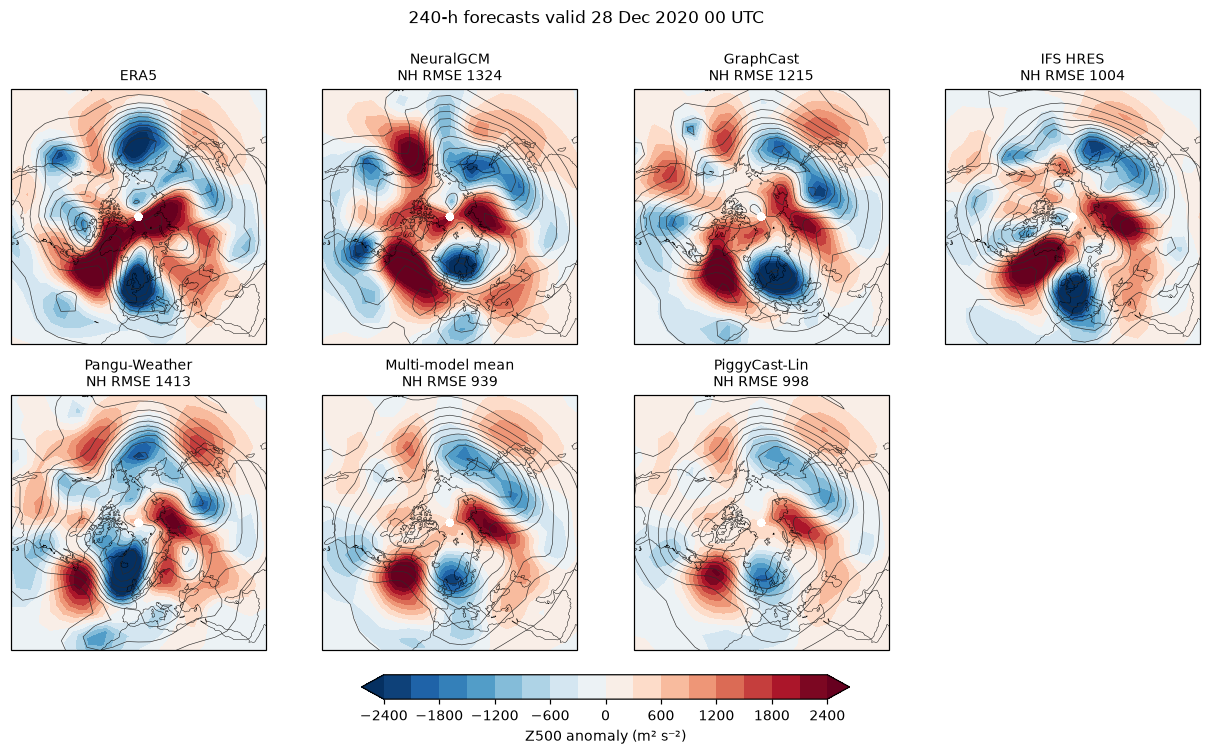

In [20]:
import sys
HAVE_DATA = (DATA / "forecasts_z500_2020.nc").exists()
if HAVE_DATA:
    sys.argv = ["exp.py", str(DATA), str(RES)]
    sys.path.insert(0, str(ROOT / "src"))
    import exp
    from cartopy.util import add_cyclic_point
    _cache = {}
    def case(lead=240, valid="2020-12-28T00"):
        if lead not in _cache:
            F, y, c = exp.build(lead)
            stack = np.stack([F[m] for m in exp.MODELS], -1)
            lin = np.full_like(y, np.nan)
            for tr, te in exp.folds(exp.GAP0 + lead // 24 * exp.STEPS_PER_DAY):
                X = np.column_stack([stack[tr].reshape(-1, 4), np.ones(len(tr) * exp.NPIX), c[tr].ravel()])
                coef = exp.wls(X, y[tr].ravel(), np.tile(exp.w, len(tr)))
                lin[te] = (np.column_stack([stack[te].reshape(-1, 4), np.ones(len(te) * exp.NPIX), c[te].ravel()]) @ coef).reshape(len(te), -1)
            _cache[lead] = (F, y, c, stack.mean(-1), lin)
        F, y, c, mmm, lin = _cache[lead]
        t = exp.VALID.get_loc(pd.Timestamp(valid))
        assert not np.isnan(lin[t, 0]), "date is not in a test window (test period starts 2020-03-08)"
        wnh = exp.w * (exp.LAT > 30)
        rm_ = lambda p: np.sqrt((((p - y[t]) ** 2) * wnh).sum() / wnh.sum())
        fields = [("ERA5", y[t]), *[(NAMES[m], F[m][t]) for m in M], ("Multi-model mean", mmm[t]), ("PiggyCast-Lin", lin[t])]
        fig, axs = plt.subplots(2, 4, figsize=(14, 7.2), subplot_kw=dict(projection=ccrs.NorthPolarStereo()))
        for ax, (name, f) in zip(axs.ravel(), fields):
            a, lonc = add_cyclic_point((f - c[t]).reshape(32, 64), coord=lon)
            full, _ = add_cyclic_point(f.reshape(32, 64), coord=lon)
            ax.set_extent([-180, 180, 25, 90], ccrs.PlateCarree())
            cf = ax.contourf(lonc, lat, a, levels=np.arange(-2400, 2401, 300), cmap="RdBu_r", extend="both", transform=ccrs.PlateCarree())
            ax.contour(lonc, lat, full, levels=np.arange(48000, 60001, 1000), colors="#2b2b2b", linewidths=.4, transform=ccrs.PlateCarree())
            ax.coastlines(lw=.3)
            ax.set_title(name + ("" if name == "ERA5" else f"\nNH RMSE {rm_(f):.0f}"), fontsize=9)
        axs.ravel()[-1].set_visible(False)
        fig.colorbar(cf, ax=axs, orientation="horizontal", fraction=.04, pad=.04, label="Z500 anomaly (m² s⁻²)")
        fig.suptitle(f"{lead}-h forecasts valid {pd.Timestamp(valid):%d %b %Y %H} UTC")
        plt.show()
    case(240, "2020-12-28T00")
else:
    print("data/ not found: skipping the case-study explorer (sections 1-9 do not need it).")

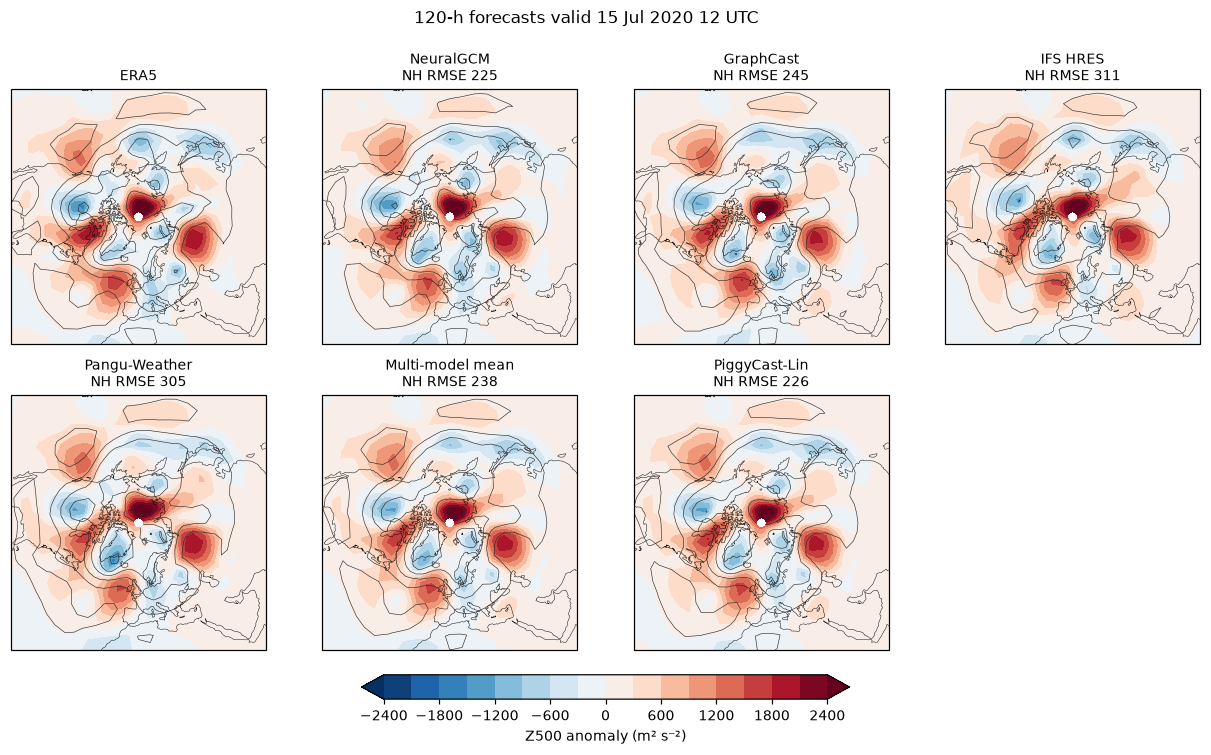

In [21]:
# Try your own: any lead in 24..240 (multiple of 24) and any 00/12 UTC valid time from 2020-03-08 to 2021-01-01.
if HAVE_DATA:
    case(120, "2020-07-15T12")

## 11. Open questions for co-authors / reviewers

1. **Framing.** The paper presents PiggyCast as a *stacking framework*, with the six-parameter linear stack as the main result and the thesis XGBoost as a negative but informative result. Is that the right emphasis?
2. **NeuralGCM initialisation.** The paper says NeuralGCM's WB2 forecasts are ERA5-initialised (per Kochkov et al. 2024), while GraphCast and Pangu (`hres_init`) start from the HRES analysis. Please confirm, since this affects the fairness discussion.
3. **Damping.** At long leads, part of PiggyCast-Lin's gain is learned damping toward climatology (activity ≈ ACC; see §2a). Should the paper show an extremes-oriented or spectral metric to make this trade-off clear?
4. **More data / resolution.** WB2 has NeuralGCM and operational GraphCast only for 2020, and NeuralGCM only down to 0.7°. Possible extensions: (a) a 2-model multi-year run (IFS HRES + Pangu `hres_init`, 2020–2022) to test how XGBoost scales with more data; (b) all four models at 1.5°. Worth it before submission?
5. **More variables.** Only Z500 so far. T850 / T2m would help show the result generalises.

> 💬 Add comments below.